# Actividad: Análisis de Datos de Diabetes

En esta actividad trabajarás con un conjunto de datos de pacientes con diabetes para poner en práctica la carga, exploración y análisis visual de datos utilizando Python con `Pandas`, `Matplotlib` y `Seaborn`. Cargarás el dataset desde Google Drive, observarás las primeras filas, revisarás estadísticas descriptivas y generarás histogramas y boxplots para analizar la distribución de las variables numéricas. También graficarás la distribución de clases diagnósticas mediante **gráficos de barras** y explorarás las distribuciones de variables usando **gráficos de densidad (KDE)** diferenciados por clase, con el objetivo de identificar patrones y diferencias entre grupos de pacientes según su diagnóstico de diabetes. Las clases diagnósticas son:

- `Y` → Diabético  
- `N` → No diabético  
- `P` → Prediabético

### Objetivo

Desarrollar habilidades en la exploración y visualización de datos en Python mediante el uso de Pandas, Matplotlib y Seaborn, aplicando gráficos estadísticos como histogramas, boxplots, gráficos de barras y gráficos de densidad KDE para analizar y comparar variables numéricas en un conjunto de datos de pacientes con diabetes, identificando posibles patrones en función de las clases de diagnóstico.

### Instrucciones

1. Asegúrate de haber montado tu Google Drive y cargado correctamente el archivo `Dataset of Diabetes.csv`.
2. Genera gráficos de distribución KDE para cada variable numérica, diferenciando por la clase `CLASS`.
3. Interpreta los resultados visuales y reflexiona sobre qué variables permiten diferenciar mejor entre las clases.

> **Nota importante:** Este dataset no contiene fechas, por lo que en lugar de series temporales se trabaja con distribuciones de variables numéricas.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Paso 1: Conectar con Google Drive

Asegúrate de haber subido el archivo Dataset of Diabetes.csv a una carpeta en tu Google Drive. Luego, monta tu Drive e indica la ruta correcta hacia el archivo.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Paso 2: Leer el archivo CSV

Reemplaza la ruta del archivo por la ubicación exacta dentro de tu Drive. Por ejemplo:

In [13]:
# Ajusta la ruta según la carpeta donde subiste el archivo
ruta_archivo = '/content/drive/MyDrive/Colab Notebooks/Curso Analítica de Datos/Dataset of Diabetes.csv'

# Cargar el dataset
df = pd.read_csv(ruta_archivo)

# eliminar espacio en blanco al inicio y al final sobre la columna CLASS
df['CLASS'] = df['CLASS'].str.strip()

# Mostrar las primeras filas
df.head()

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,M,26,4.5,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,F,50,4.7,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,M,33,7.1,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N


## Exploración Inicial del Dataset

Una vez que hayas cargado el archivo correctamente, es momento de explorar la estructura del conjunto de datos para familiarizarte con sus variables, tipos de datos y características generales.

### Paso 3: Examinar la estructura del DataFrame

Utiliza los siguientes comandos para revisar la información general del conjunto de datos:

In [14]:
# Mostrar información general del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB


Esto te permitirá verificar cuántas columnas hay, los tipos de datos, y cuántos valores no nulos existen por columna.

### Paso 4: Estadísticas descriptivas

Usa .describe() para obtener un resumen estadístico de las columnas numéricas:

In [15]:
# Mostrar estadísticas descriptivas del DataFrame
df.describe()

,ID,No_Pation,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI
count,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,340.500000,2.705514e+05,53.528000,5.124743,68.943000,8.281160,4.862820,2.349610,1.204750,2.609790,1.854700,29.578020
std,240.397673,3.380758e+06,8.799241,2.935165,59.984747,2.534003,1.301738,1.401176,0.660414,1.115102,3.663599,4.962388
min,1.000000,1.230000e+02,20.000000,0.500000,6.000000,0.900000,0.000000,0.300000,0.200000,0.300000,0.100000,19.000000
25%,125.750000,2.406375e+04,51.000000,3.700000,48.000000,6.500000,4.000000,1.500000,0.900000,1.800000,0.700000,26.000000
50%,300.500000,3.439550e+04,55.000000,4.600000,60.000000,8.000000,4.800000,2.000000,1.100000,2.500000,0.900000,30.000000
75%,550.250000,4.538425e+04,59.000000,5.700000,73.000000,10.200000,5.600000,2.900000,1.300000,3.300000,1.500000,33.000000
max,800.000000,7.543566e+07,79.000000,38.900000,800.000000,16.000000,10.300000,13.800000,9.900000,9.900000,35.000000,47.750000


## Visualización de Distribuciones y Detección de Posibles Valores Atípicos

Visualizar los datos te permite observar la forma en que se distribuyen las variables, identificar posibles valores atípicos y detectar errores comunes como ceros imposibles o valores extremos.

### Paso 5: Histogramas de las variables numéricas

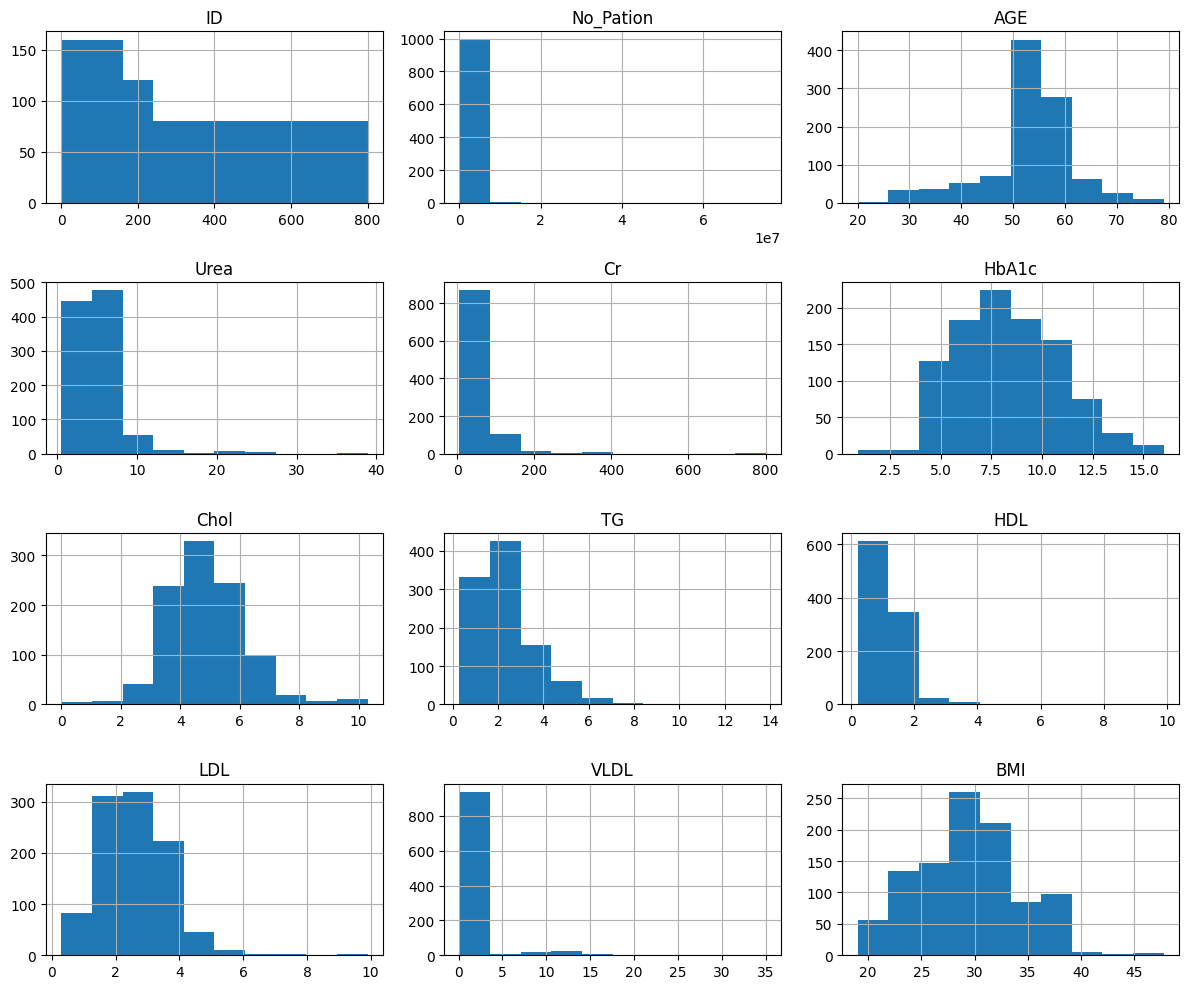

In [16]:
# Crear histogramas para todas las columnas numéricas
df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

Revisa si hay columnas con distribuciones extrañas, picos inesperados o concentraciones de ceros.

### Paso 6: Boxplots para detectar valores atípicos

Los boxplots son útiles para identificar valores atípicos visualmente.

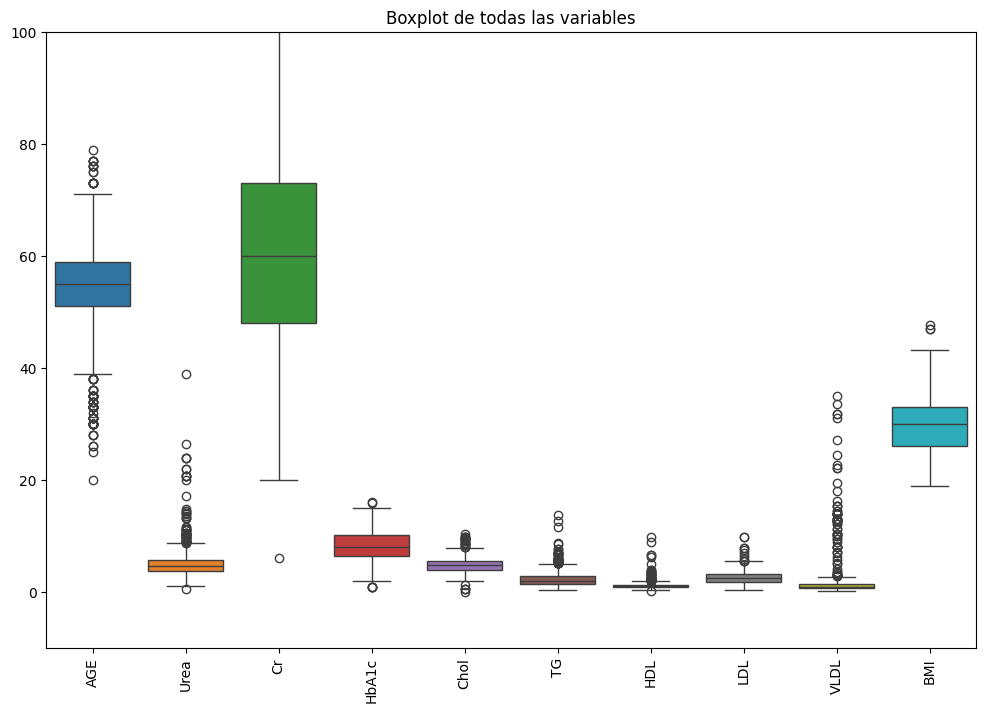

In [17]:
# Boxplot general de todas las variables numéricas
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[['Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG', 'HDL', 'LDL', 'VLDL', 'BMI', 'CLASS']])
plt.xticks(rotation=90)
plt.ylim(-10, 100)  # Ajustar el límite del eje y
plt.title("Boxplot de todas las variables")
plt.show()

### Paso 7: Explora una variable específica

Selecciona una variable que te parezca interesante y crea su boxplot de forma individual para examinarla con más detalle.

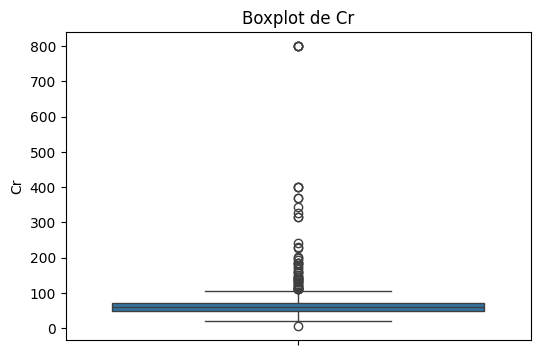

In [36]:
# Reemplaza 'NombreDeLaColumna' por una de las columnas del DataFrame
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['Cr'])  # ← COMPLETA AQUÍ
plt.title("Boxplot de Cr")
plt.show()

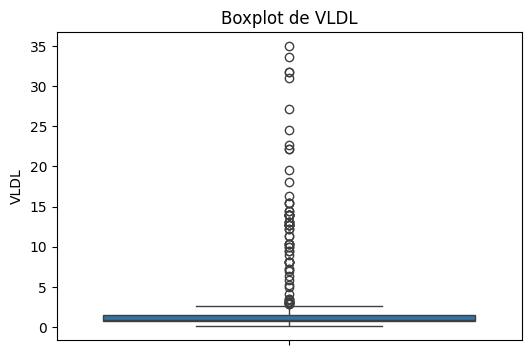

In [37]:
# Reemplaza 'NombreDeLaColumna' por una de las columnas del DataFrame
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['VLDL'])  # ← COMPLETA AQUÍ
plt.title("Boxplot de VLDL")
plt.show()

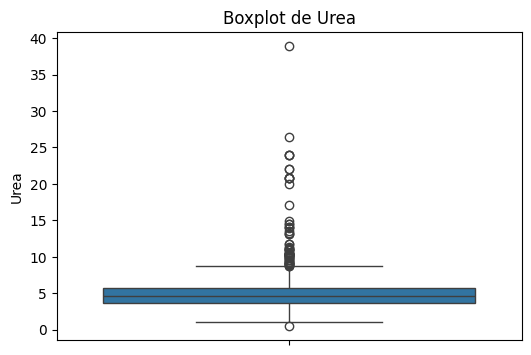

In [40]:
# Reemplaza 'NombreDeLaColumna' por una de las columnas del DataFrame
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['Urea'])  # ← COMPLETA AQUÍ
plt.title("Boxplot de Urea")
plt.show()

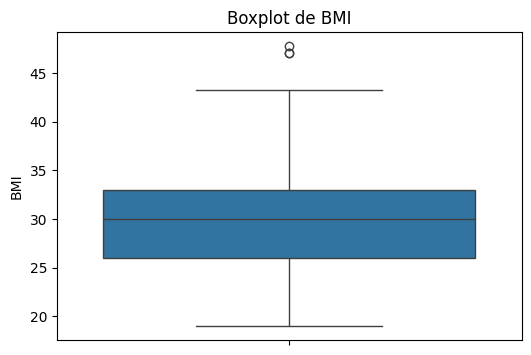

In [38]:
# Reemplaza 'NombreDeLaColumna' por una de las columnas del DataFrame
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['BMI'])  # ← COMPLETA AQUÍ
plt.title("Boxplot de BMI")
plt.show()

**Recuerda:** algunas columnas podrían tener valores fuera de lo normal (por ejemplo, presión sanguínea en cero), lo cual podría indicar errores o datos faltantes codificados incorrectamente.

## Distribución de la Variable Objetivo: Diagnóstico de Diabetes

Antes de seguir con análisis más profundos, es importante entender cómo se distribuyen las clases en la variable objetivo CLASS, que representa el diagnóstico:
	•	Y → Diabético
	•	N → No diabético
	•	P → Prediabético

### Paso 8: Volumetría por clase

Visualiza cuántos casos hay en cada una de las categorías usando un diagrama de barras:

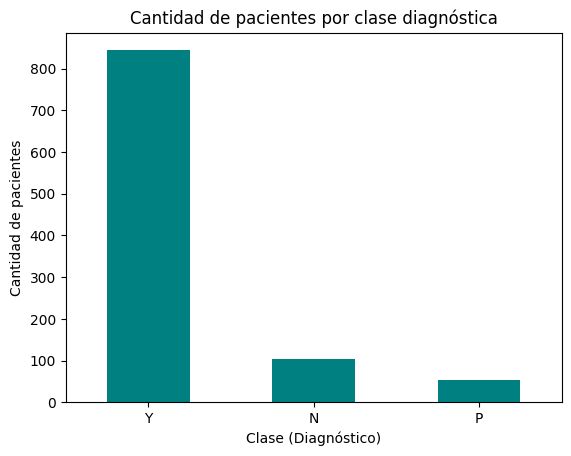

In [39]:
# Conteo de valores por clase
df['CLASS'].value_counts().plot(kind='bar', color='teal')

# Personalización del gráfico
plt.title('Cantidad de pacientes por clase diagnóstica')
plt.xlabel('Clase (Diagnóstico)')
plt.ylabel('Cantidad de pacientes')
plt.xticks(rotation=0)
plt.show()

**Objetivo:** A partir de esta gráfica, reflexiona sobre si el dataset está balanceado o si alguna clase está sobrerrepresentada.

## Preguntas de análisis

1. Observando los histogramas y boxplots, ¿qué variables podrían contener valores inválidos o poco realistas (por ejemplo, ceros o valores extremadamente altos)? ¿Por qué crees que estos valores podrían representar un problema para el análisis?
2. ¿Hay alguna clase que tenga significativamente más ejemplos que las otras?
3. ¿Qué conclusiones puedes sacar del análisis visual?

**Escribe tus respuestas en celdas debajo de esta sección.**


**Respuestas**

1. Las variables que podrían contener valores atípicos parecen ser aquellas cuyos histogramas están más sesgados hacia la derecha, es decir, los datos se concentran a la derecha, por ejemplo Cr, Urea, VLDL.
  - Estos valores pueden representar un problema porque pueden deberse a errores de medición, errores al ingresar los datos, diferencias en los métodos de estimación. Si dichos errores no se identifican y se tienen en cuenta, podrían alterar la validez de los resultados y hacer que las conclusiones no sean precisas.
2. Sí, visualmente puede verse que la clase `Y` tiene una mayor cantidad de pacientes, con una cantidad superior a 800 pacientes, en tanto que las otras clases están alrededor de los 100 pacientes según el histograma. Esto significa que de los 1000 registros, más del 80% son pertenecientes a pacientes con diabetes.
3. Se tienen varias variables con valores atípicos según los gráficos de caja, los cuales deben ser analizados para poder descartar que no se traten de error. Esto puede afectar la validez del análisis o aportar información inexacta. También se ve que la mayoría de los datos pertenecen a pacientes diagnosticados con diabetes, de acuerdo al histograma de la clase de paciente.

### Paso 9: Gráfico KDE para una variable

Utiliza sns.kdeplot() para comparar la distribución de una variable entre las tres clases. Comienza con una variable como Urea.

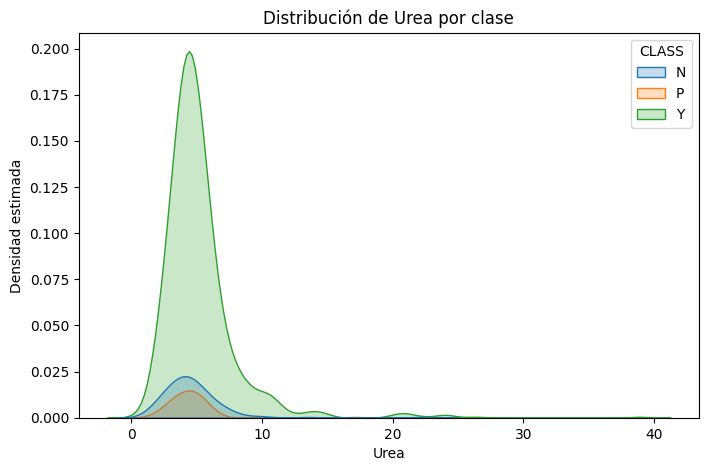

In [41]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='Urea', hue='CLASS', fill=True)
plt.title('Distribución de Urea por clase')
plt.xlabel('Urea')
plt.ylabel('Densidad estimada')
plt.show()

### Paso 10: Repite con otras variables

Copia la celda anterior y cambia el nombre de la columna para explorar otras variables. Por ejemplo: 'BMI', 'Insulin', 'BloodPressure', 'Age'.

> Puedes probar con una por una y observar si las curvas se separan claramente entre clases. Deja solo las imagenes de las variables que consideres más relevantes para el análisis. No es necesario mantener las gráficas para todas las variables.

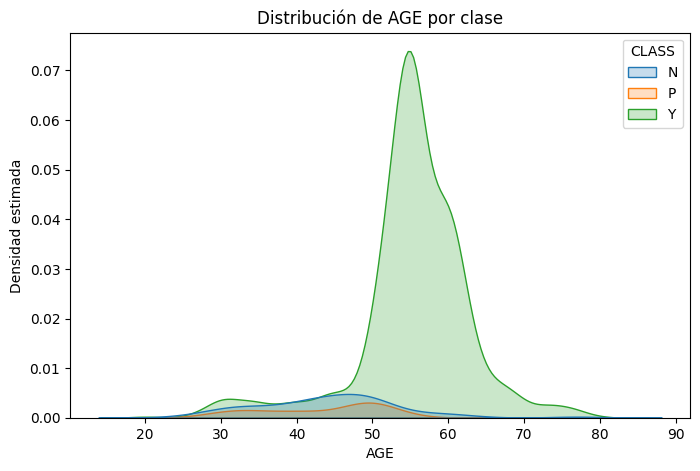

In [42]:
### Tu código aquí
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='AGE', hue='CLASS', fill=True)
plt.title('Distribución de AGE por clase')
plt.xlabel('AGE')
plt.ylabel('Densidad estimada')
plt.show()

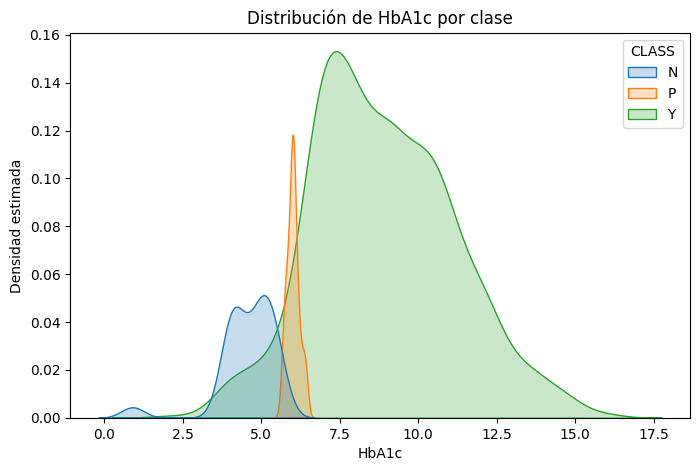

In [44]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='HbA1c', hue='CLASS', fill=True)
plt.title('Distribución de HbA1c por clase')
plt.xlabel('HbA1c')
plt.ylabel('Densidad estimada')
plt.show()

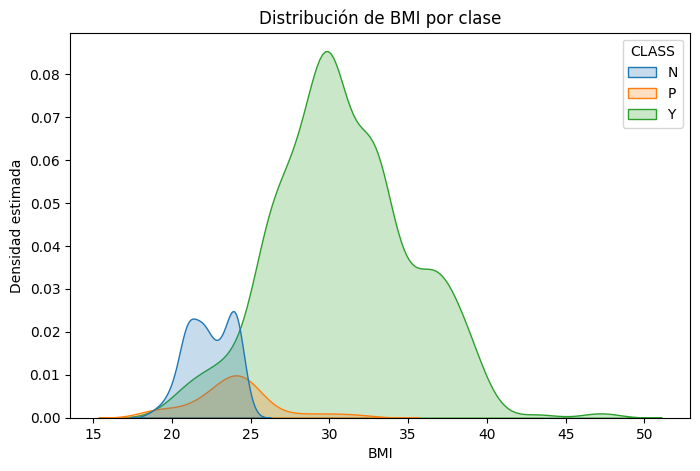

In [50]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='BMI', hue='CLASS', fill=True)
plt.title('Distribución de BMI por clase')
plt.xlabel('BMI')
plt.ylabel('Densidad estimada')
plt.show()

## Preguntas de análisis

Por cada variable que explores, responde:
- ¿Se observan diferencias claras entre las clases?
- ¿Alguna clase tiene una distribución completamente diferente?
- ¿Crees que esta variable podría ayudar a predecir el diagnóstico?

Escribe tus respuestas en una celda de texto después de cada gráfico.

**Respuesta**

1. Se escogieron las variables de edad (`AGE`), hemoglobina glicosada (`HbA1c`) y el indice de masa corporal (`BMI`), dado que para estas las distribuciones se concentran en diferentes valores.
2. Sí, para el caso de `HbA1c` se observa una distribución concentrada en dos valores para la clase de pacientes No diabéticos (`N`). También, se observa una concentración muy alta de la densidad para los pacientes Prediabéticos (`P`).
3. Sí, estas variables podrían ayudar a predecir el diagnóstico de acuerdo a lo siguiente:
  - Para la variable `AGE`, la densidad estimada se concentra entre los 50 a 60 años, mientras que para las otras dos clases, estas se concentran en edades menores. Esto que podría indicar que al aumentar la edad, hay una relación con el diagnóstico positivo en diabetes.
  - El `HbA1c` parece estar directamente relacionado con un diagnóstico de diabetes. Se muestra que valores altos de esta variable están relacionados con pacientes prediabéticos y diabéticos según los datos.
  - Finalmente, el `BMI` también parece relacionarse directamente con los pacientes diabéticos. La densidad del BMI para los pacientes diabéticos está concentrada en valores altos a diferencia de la distribución de los pacientes prediabéticos y no diabéticos, que se concentra alrededor de valores bajos de BMI.